# Single qubit Gates

To make our quantum program more interesting, between initializing the qubits and measuring them, we will perform some operations.  

An important feature of quantum circuits is that the operations (gates) are always reversible!  

These reversible gates can be represented as matrices, and as rotations around the Bloch sphere. 

Let's implement some of the most important operations:

In [2]:
from qiskit import QuantumCircuit, Aer  #assemble,
from math import pi, sqrt
from qiskit.visualization import plot_bloch_multivector, plot_histogram

sim = Aer.get_backend('aer_simulator')

### Exercices:
* Show that applying the sequence of gates: HZH, to any qubit state is equivalent to applying an X-gate.  
* Find a combination of X, Z and H-gates that is equivalent to a Y-gate (ignoring global phase).

### How to measure in the x-basis
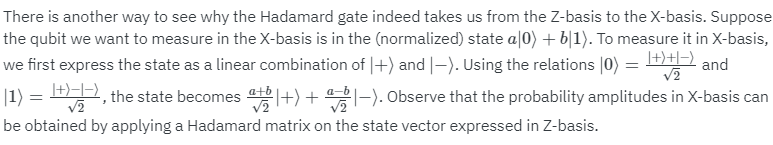


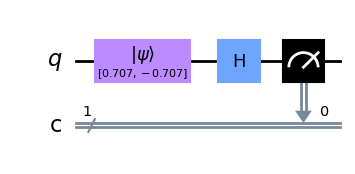

In [5]:
# Create the X-measurement function:
def x_measurement(qc, qubit, cbit):
    """Measure 'qubit' in the X-basis, and store the result in 'cbit'"""
    qc.h(qubit)
    qc.measure(qubit, cbit)
    return qc

initial_state = [1/sqrt(2), -1/sqrt(2)]
# Initialize our qubit and measure it
qc = QuantumCircuit(1,1)
qc.initialize(initial_state, 0)
x_measurement(qc, 0, 0)  # measure qubit 0 to classical bit 0
qc.draw()

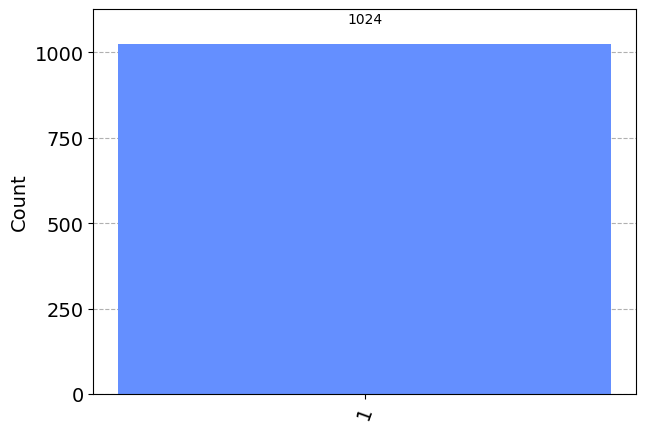

In [6]:
## Let's see the results of the measurement:
counts = sim.run(qc).result().get_counts()  # Do the simulation, returning the state vector
plot_histogram(counts)  # Display the output on measurement of state vector

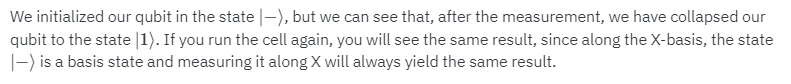

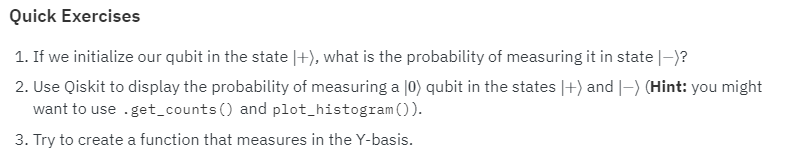

# Perform operations with Operators and Statevectors

In [7]:
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram, plot_bloch_vector
from numpy import sqrt
## define unitary operations using the Operator class
X = Operator([ [0,1],[1,0] ])
Y = Operator([ [0,-1.j],[1.j,0] ])
Z = Operator([ [1,0],[0,-1] ])
H = Operator([ [1/sqrt(2),1/sqrt(2)],[1/sqrt(2),-1/sqrt(2)] ])
S = Operator([ [1,0],[0,1.j] ])
T = Operator([ [1,0],[0,(1+1.j)/sqrt(2)] ])

v = Statevector([1,0])

v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(Z)

v.draw('latex')

<IPython.core.display.Latex object>

In [8]:
v.measure()

('0',
 Statevector([0.92387953+0.38268343j, 0.        +0.j        ],
             dims=(2,)))

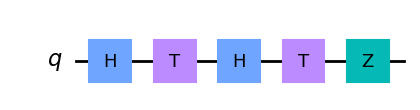

In [9]:
## Quantum circuits can be used to define composed unitary operation too
## this is using the quantum circuit class

from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.t(0)
circuit.z(0)

circuit.draw()

The operations are applied sequentially, starting on the left and ending on the right in the figure. Let us first initialize a starting quantum state vector and then evolve that state according to the sequence of operations.

In [10]:
ket0 = Statevector([1,0])
v = ket0.evolve(circuit)
v.draw('latex')

<IPython.core.display.Latex object>

Finally, let's simulate the result of running this experiment (i.e., preparing the state , applying the sequence of operations represented by the circuit, and measuring) 4000 times.

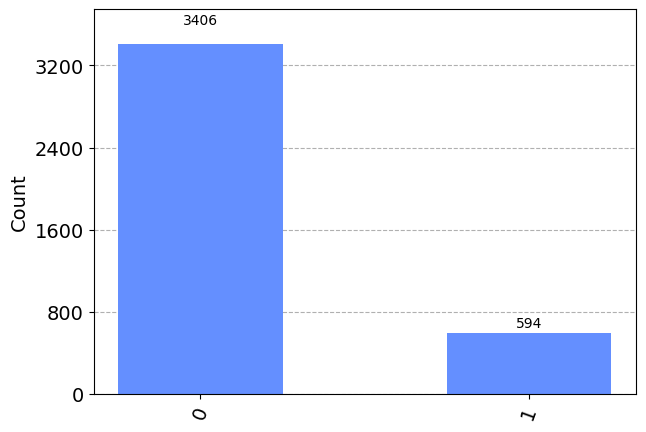

In [11]:
statistics = v.sample_counts(4000)
plot_histogram(statistics)